# Nama: Inayah Syafa Shalihah Prayitno
# NIM: 2404010020


Netflix Titles — Data Preprocessing

Tujuan: melakukan pemeriksaan kualitas data, membersihkan data, melakukan transformasi, lalu membandingkan kondisi sebelum dan sesudah preprocessing.

**1. Import library dan upload dataset**

Mengupload dataset dari kaggle ke dalam colab

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

uploaded = files.upload()
file_name = next(iter(uploaded))

df_raw = pd.read_csv(file_name)
df = df_raw.copy()

print("Dataset berhasil dibaca.")
print("Jumlah baris dan kolom:", df.shape)
display(df.head())

Saving netflix_titles.csv.zip to netflix_titles.csv.zip
Dataset berhasil dibaca.
Jumlah baris dan kolom: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


**2. Memahami kondisi awal dataset**

Memeriksa ukuran data, tipe data, statistik, dan jumlah nilai kosong sebelum melakukan perubahan.

In [3]:
print("Ukuran dataset:", df.shape)
print("\\nInformasi kolom:")
df.info()

print("\\nStatistik deskriptif:")
display(df.describe(include="all").T)

print("\\nJumlah baris duplikat identik:", df.duplicated().sum())

Ukuran dataset: (8807, 12)
\nInformasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
\nStatistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s8807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Zubaan,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nJumlah baris duplikat identik: 0


**3. Laporan kualitas data awal**

Persentase missing values dihitung terhadap jumlah baris. Hasil ini menjadi baseline untuk dibandingkan dengan hasil akhir.

In [4]:
def quality_report(data):
    report = pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "missing_count": data.isna().sum(),
        "missing_percent": (data.isna().mean() * 100).round(2),
        "unique_values": data.nunique(dropna=True)
    })
    return report.sort_values("missing_count", ascending=False)

report_before = quality_report(df)
display(report_before)

,dtype,missing_count,missing_percent,unique_values
director,object,2634,29.91,4528
country,object,831,9.44,748
cast,object,825,9.37,7692
date_added,object,10,0.11,1767
rating,object,4,0.05,17
duration,object,3,0.03,220
show_id,object,0,0.00,8807
type,object,0,0.00,2
title,object,0,0.00,8807
release_year,int64,0,0.00,74


**4. Periksa nilai yang tidak konsisten**

Pada dataset ini, beberapa nilai di kolom rating ternyata berbentuk durasi (misalnya 74 min), sementara kolom duration pada baris tersebut kosong. Kita periksa dulu sebelum memperbaikinya.

In [5]:
# Periksa nilai rating yang terlihat seperti durasi
mask_rating_duration = df["rating"].astype("string").str.contains(r"^\\s*\\d+\\s+min\\s*$", case=False, na=False)
display(df.loc[mask_rating_duration, ["show_id", "title", "rating", "duration"]])

# Periksa baris yang memiliki duration kosong
display(df.loc[df["duration"].isna(), ["show_id", "title", "rating", "duration"]])

,show_id,title,rating,duration


,show_id,title,rating,duration
5541,s5542,Louis C.K. 2017,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,66 min,NaN


**5. Membersihkan spasi dan teks**

Kolom teks dibersihkan dari spasi di awal/akhir. Nilai kosong tidak diubah menjadi string pada tahap ini agar tetap bisa dianalisis.

In [6]:
text_cols = df.select_dtypes(include=["object", "string"]).columns

for col in text_cols:
    df[col] = df[col].apply(lambda value: value.strip() if isinstance(value, str) else value)

print("Pembersihan spasi selesai.")
display(df.head())

Pembersihan spasi selesai.


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


**6. Memperbaiki nilai durasi yang salah kolom**

Jika rating berisi format angka + min dan duration kosong, pindahkan nilai tersebut ke duration lalu kosongkan rating. Ini berdasarkan temuan pemeriksaan di atas, bukan asumsi untuk semua baris.

In [7]:
mask_rating_duration = df["rating"].astype("string").str.contains(r"^\\d+\\s+min$", case=False, na=False)
mask_duration_empty = df["duration"].isna()
mask_fix = mask_rating_duration & mask_duration_empty

print("Jumlah baris yang akan diperbaiki:", int(mask_fix.sum()))

df.loc[mask_fix, "duration"] = df.loc[mask_fix, "rating"]
df.loc[mask_fix, "rating"] = np.nan

display(df.loc[mask_fix, ["show_id", "title", "rating", "duration"]])

Jumlah baris yang akan diperbaiki: 0


,show_id,title,rating,duration


**7. Mengubah tipe data tanggal**

Kolom date_added awalnya berupa teks. Ubah menjadi tipe datetime agar bisa dipakai untuk analisis tanggal. Nilai yang tidak dapat dibaca akan menjadi NaT dan perlu dievaluasi.

In [8]:
df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

print("Tipe data date_added:", df["date_added"].dtype)
print("Nilai tanggal kosong/tidak terbaca:", int(df["date_added"].isna().sum()))

Tipe data date_added: datetime64[ns]
Nilai tanggal kosong/tidak terbaca: 10


**8. Menangani missing values**

Untuk kolom kategori/teks, nilai kosong diisi label Unknown agar informasi bahwa datanya tidak tersedia tetap terlihat. Untuk date_added, kita biarkan kosong karena tanggal yang tidak diketahui sebaiknya tidak dibuat-buat.

In [9]:
categorical_text_cols = [
    "director", "cast", "country", "rating"
]

for col in categorical_text_cols:
    df[col] = df[col].fillna("Unknown")

# date_added sengaja tidak diimputasi karena tidak ada dasar untuk menebak tanggalnya.
print("Missing values setelah penanganan:")
display(df.isna().sum().to_frame("missing_count").query("missing_count > 0"))

Missing values setelah penanganan:


,missing_count
date_added,10
duration,3


**9. Transformasi kolom duration**

Pisahkan durasi menjadi angka (duration_value) dan satuan (duration_unit). Ini memudahkan analisis, karena film umumnya memakai menit dan serial memakai musim. Kolom duration asli tetap dipertahankan.

In [10]:
duration_parts = df["duration"].astype("string").str.extract(
    r"^\\s*(\\d+)\\s*(min|seasons?)\\s*$",
    expand=True
)

df["duration_value"] = pd.to_numeric(duration_parts[0], errors="coerce")
df["duration_unit"] = duration_parts[1].str.lower()

# Samakan label satuan season agar konsisten
df["duration_unit"] = df["duration_unit"].replace({"season": "seasons"})

display(df[["title", "type", "duration", "duration_value", "duration_unit"]].head(10))

,title,type,duration,duration_value,duration_unit
0,Dick Johnson Is Dead,Movie,90 min,<NA>,<NA>
1,Blood & Water,TV Show,2 Seasons,<NA>,<NA>
2,Ganglands,TV Show,1 Season,<NA>,<NA>
3,Jailbirds New Orleans,TV Show,1 Season,<NA>,<NA>
4,Kota Factory,TV Show,2 Seasons,<NA>,<NA>
5,Midnight Mass,TV Show,1 Season,<NA>,<NA>
6,My Little Pony: A New Generation,Movie,91 min,<NA>,<NA>
7,Sankofa,Movie,125 min,<NA>,<NA>
8,The Great British Baking Show,TV Show,9 Seasons,<NA>,<NA>
9,The Starling,Movie,104 min,<NA>,<NA>


**10. Pemeriksaan outlier (tidak otomatis menghapus)**

Gunakan boxplot dan metode IQR sebagai alat pemeriksaan awal. Nilai di luar batas IQR belum tentu salah, misalnya film yang sangat panjang bisa saja valid.

release_year: batas IQR=(2004.00, 2028.00); jumlah kandidat outlier=719


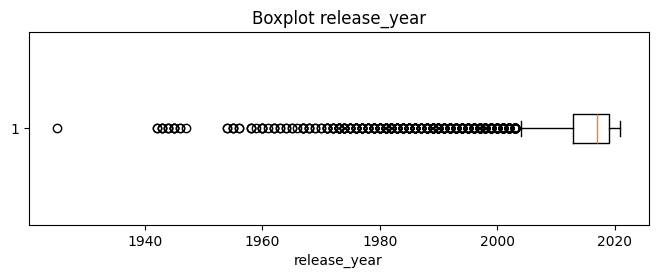

In [11]:
numeric_cols = ["release_year", "duration_value"]

for col in numeric_cols:
    values = df[col].dropna()
    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outlier_count = int(((values < lower) | (values > upper)).sum())

    print(f"{col}: batas IQR=({lower:.2f}, {upper:.2f}); jumlah kandidat outlier={outlier_count}")

    plt.figure(figsize=(8, 2.5))
    plt.boxplot(values, vert=False)
    plt.title(f"Boxplot {col}")
    plt.xlabel(col)
    plt.show()

**11. Periksa duplikasi dan validitas akhir**

Hapus hanya baris yang benar-benar duplikat identik. Setelah itu, periksa nilai kosong dan tipe data sekali lagi.

In [12]:
duplicates_before = int(df.duplicated().sum())
df_clean = df.drop_duplicates().copy()

print("Duplikat identik sebelum:", duplicates_before)
print("Duplikat identik setelah:", int(df_clean.duplicated().sum()))
print("Ukuran akhir:", df_clean.shape)

display(quality_report(df_clean))
print("\\nTipe data akhir:")
print(df_clean.dtypes)

Duplikat identik sebelum: 0
Duplikat identik setelah: 0
Ukuran akhir: (8807, 14)


,dtype,missing_count,missing_percent,unique_values
duration_unit,string,8807,100.00,0
duration_value,Float64,8807,100.00,0
date_added,datetime64[ns],10,0.11,1714
duration,object,3,0.03,220
show_id,object,0,0.00,8807
type,object,0,0.00,2
country,object,0,0.00,749
cast,object,0,0.00,7693
director,object,0,0.00,4529
title,object,0,0.00,8806


\nTipe data akhir:
show_id                   object
type                      object
title                     object
director                  object
cast                      object
country                   object
date_added        datetime64[ns]
release_year               int64
rating                    object
duration                  object
listed_in                 object
description               object
duration_value           Float64
duration_unit     string[python]
dtype: object


**12. Bandingkan sebelum dan sesudah preprocessing**

Perhatikan bahwa jumlah missing values bisa berubah karena penanganan nilai kosong dan perbaikan data yang salah kolom. Bandingkan hasilnya dan jelaskan alasan setiap perubahan di laporan.

In [13]:
comparison = pd.DataFrame({
    "missing_before": df_raw.isna().sum(),
    "missing_after": df_clean.isna().sum()
})
comparison["change"] = comparison["missing_after"] - comparison["missing_before"]

display(comparison)
print("Ukuran sebelum:", df_raw.shape)
print("Ukuran sesudah:", df_clean.shape)

,missing_before,missing_after,change
cast,825.0,0,-825.0
country,831.0,0,-831.0
date_added,10.0,10,0.0
description,0.0,0,0.0
director,2634.0,0,-2634.0
duration,3.0,3,0.0
duration_unit,NaN,8807,NaN
duration_value,NaN,8807,NaN
listed_in,0.0,0,0.0
rating,4.0,0,-4.0


Ukuran sebelum: (8807, 12)
Ukuran sesudah: (8807, 14)


In [14]:
output_csv = "netflix_titles_preprocessed.csv"
df_clean.to_csv(output_csv, index=False)

print("File tersimpan:", output_csv)
files.download(output_csv)

File tersimpan: netflix_titles_preprocessed.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>